In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [8]:
df = pd.read_csv("/Users/omikapatel/Desktop/Python_Decal/course_assignments/homework9/solar_system.csv")
print(df.shape) # 20 x 11
print(df.head)
print(df.tail)

for col in df.columns:
    print(col)
for row in df.index:
    print(row)

(20, 11)
<bound method NDFrame.head of                       Attribute Mercury    Venus  Earth   Moon   Mars  \
0                Mass (10^24kg)   0.330     4.87   5.97  0.073  0.642   
1                 Diameter (km)    4879    12104  12756   3475   6792   
2              Density (kg/m^3)    5429     5243   5514   3340   3934   
3               Gravity (m/s^2)     3.7      8.9    9.8    1.6    3.7   
4        Escape Velocity (km/s)     4.3     10.4   11.2    2.4    5.0   
5       Rotation Period (hours)  1407.6  -5832.5   23.9  655.7   24.6   
6         Length of Day (hours)  4222.6   2802.0   24.0  708.7   24.7   
7   Distance from Sun (10^6 km)    57.9    108.2  149.6  0.384  228.0   
8          Perihelion (10^6 km)    46.0    107.5  147.1  0.363  206.7   
9            Aphelion (10^6 km)    69.8    108.9  152.1  0.406  249.3   
10        Orbital Period (days)    88.0    224.7  365.2   27.3  687.0   
11      Orbital Velocity (km/s)    47.4     35.0   29.8    1.0   24.1   
12    Orbita

In [9]:
orbital_period = df.iloc[0, 1:].astype(float) 
perihelion = df.iloc[1, 1:].astype(float) # closest point to host star in planet orbit
aphelion = df.iloc[2, 1:].astype(float) # farthest point to host star in planet orbit
# semi major axis: half the longest diameter or orbit (avg of per/aph values)

In [11]:
semi_major_axis = (perihelion + aphelion) / 2

new_row = pd.Series(semi_major_axis)
new_row[df.columns[0]] = 'Semi-major axis (10^6 km)'
df = pd.concat([df, new_row.to_frame().T], ignore_index=True)

print(df.shape) # 21 x 11

(22, 11)
Rows: 22
Columns: 11


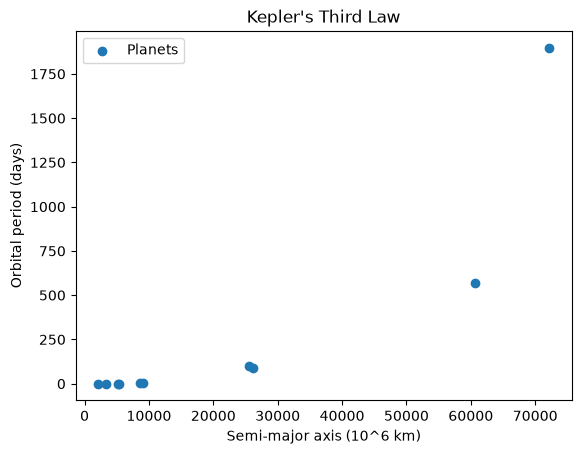

In [12]:
plt.scatter(semi_major_axis, orbital_period, label='Planets')

plt.xlabel('Semi-major axis (10^6 km)')
plt.ylabel('Orbital period (days)')
plt.title("Kepler's Third Law")
plt.legend()
plt.show()

Fit: T = 0.00 * a^1.5
66815.86562608539


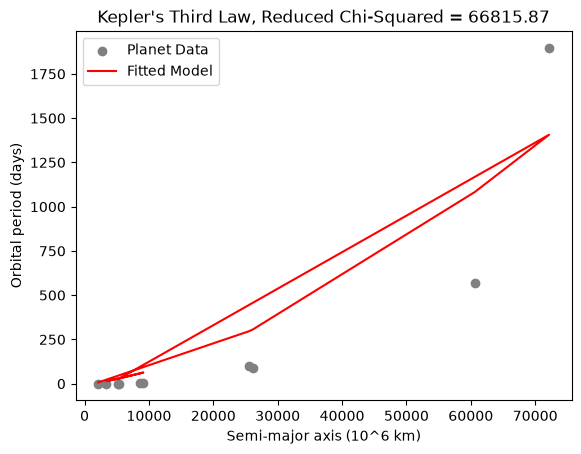

In [14]:
def keplers_third_law(a, m):
    return m * a ** 1.5

popt, pcov = curve_fit(keplers_third_law, semi_major_axis,
                       orbital_period)
m_fit = popt[0]
print(f"Fit: T = {m_fit:.2f} * a^1.5")

residuals = orbital_period - keplers_third_law(semi_major_axis, m_fit)
chi2 = np.sum(residuals**2)
dof = len(semi_major_axis) - len(popt)
chi2_reduced = chi2 / dof
print(chi2_reduced)

plt.scatter(semi_major_axis, orbital_period,
            color='gray', label='Planet Data')
plt.plot(semi_major_axis, keplers_third_law(semi_major_axis, m_fit),
         color='red', label='Fitted Model')
plt.xlabel('Semi-major axis (10^6 km)')
plt.ylabel('Orbital period (days)')
plt.title(f"Kepler's Third Law, Reduced Chi-Squared = {chi2_reduced:.2f}")
plt.legend()

plt.show() # uhh

In [15]:
df.to_csv("kepler.csv", index=False)

In [16]:
print(df)

                      Attribute Mercury    Venus   Earth    Moon    Mars  \
0                Mass (10^24kg)   0.330     4.87    5.97   0.073   0.642   
1                 Diameter (km)    4879    12104   12756    3475    6792   
2              Density (kg/m^3)    5429     5243    5514    3340    3934   
3               Gravity (m/s^2)     3.7      8.9     9.8     1.6     3.7   
4        Escape Velocity (km/s)     4.3     10.4    11.2     2.4     5.0   
5       Rotation Period (hours)  1407.6  -5832.5    23.9   655.7    24.6   
6         Length of Day (hours)  4222.6   2802.0    24.0   708.7    24.7   
7   Distance from Sun (10^6 km)    57.9    108.2   149.6   0.384   228.0   
8          Perihelion (10^6 km)    46.0    107.5   147.1   0.363   206.7   
9            Aphelion (10^6 km)    69.8    108.9   152.1   0.406   249.3   
10        Orbital Period (days)    88.0    224.7   365.2    27.3   687.0   
11      Orbital Velocity (km/s)    47.4     35.0    29.8     1.0    24.1   
12    Orbita